In [1]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
az.style.use('arviz-white')

## Gaussian inferences
### The following example corresponds to experimental measurements in nuclear magnetic resonance, a technique to study molecules and also living things (because, after all, they are just a bunch of molecules).

### In this example, we have 48 measurements:



In [3]:
data = np.array([51.06, 55.12, 53.73, 50.24, 52.05, 56.40, 48.45,
52.34, 55.65, 51.49, 51.86, 63.43, 53.00, 56.09, 51.93, 52.31, 52.33,
57.48, 57.44, 55.14, 53.93, 54.62, 56.09, 68.58, 51.36, 55.47, 50.73,51.94, 54.95, 50.39, 52.91, 51.5, 52.68, 47.72, 49.73, 51.82, 54.99,
52.84, 53.19, 54.52, 51.46, 53.73, 51.61, 49.81, 52.42, 54.3, 53.84,
53.16])

## A plot of this dataset shows a Gaussian-like distribution except for two data points far away from the mean:

/usr/local/lib/python3.10/dist-packages/arviz/utils.py:184: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  numba_fn = numba.jit(**self.kwargs)(self.function)


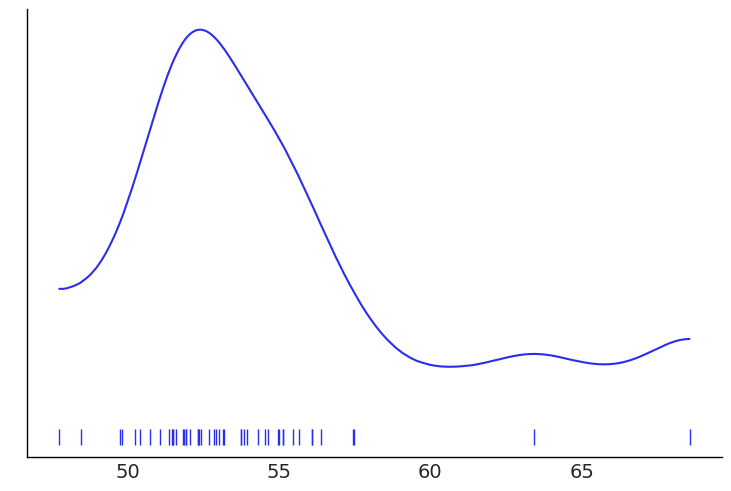

In [4]:
az.plot_kde(data, rug=True)
plt.yticks([0], alpha=0)
plt.savefig('B11197_02_07.png')

### Let's for a moment forget about those two points and assume a Gaussian distribution. Since we do not know the mean or the standard deviation, we must set priors for both of them. Then, a reasonable model could be as follows:

### $$ \mu \sim Uniform(l,h) $$

### $$ \sigma \sim HalfNormal(\sigma_h) $$

### $$ y \sim Normal(\mu,\sigma) $$

Thus, $\mu$ comes from a uniform distribution with boundaries l and h, lower and
upper respectively, and $\sigma$ comes from a half-normal distribution with standard
deviation  $\sigma_h$. A half-normal distribution is like the regular normal distribution but
restricted to positive values; it is like we have folded the normal distribution by its
mean. Finally, in our model, the data y comes from a normal distribution with the
parameters $\mu$ and $\sigma$. Using Kruschke-style diagrams, we have the following:

 <img src="B11197_02_08.png" width="500">

### If we do not know the possible values of $\mu$ and $\sigma$ , we can set priors reflecting our ignorance. One option is to set the boundaries of the uniform distribution to be $(l=40, h=75)$, which is a range larger than the range of the data. Alternatively, we could have chosen a wider range based, for example, on our previous knowledge. We may know that is not physically possible to have values below 0 or above 100. So we could set the prior for the mean as a uniform, with parameters $(l=0, h=100)$. For the half normal, we will use a value of $\sigma$ is equal to 10, just a large value for the data:

In [5]:
with pm.Model() as model_g:
    μ = pm.Uniform('μ', lower=40, upper=70)
    σ = pm.HalfNormal('σ', sigma=10)
    y = pm.Normal('y', mu=μ, sigma=σ, observed=data)
    idata_g = pm.sample(1000)

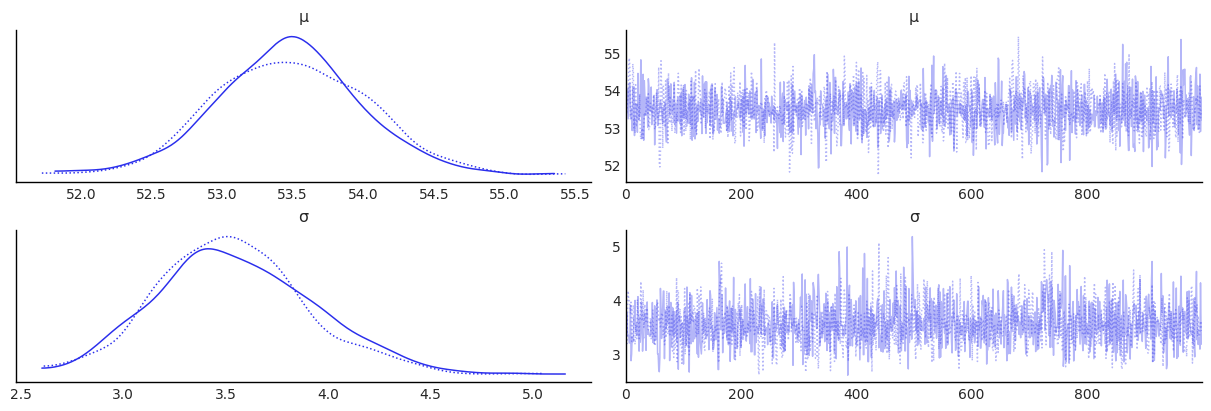

In [6]:
az.plot_trace(idata_g)
plt.savefig('B11197_02_09.png')

### We can look at the joint distribution of $\sigma$ and $\mu$.

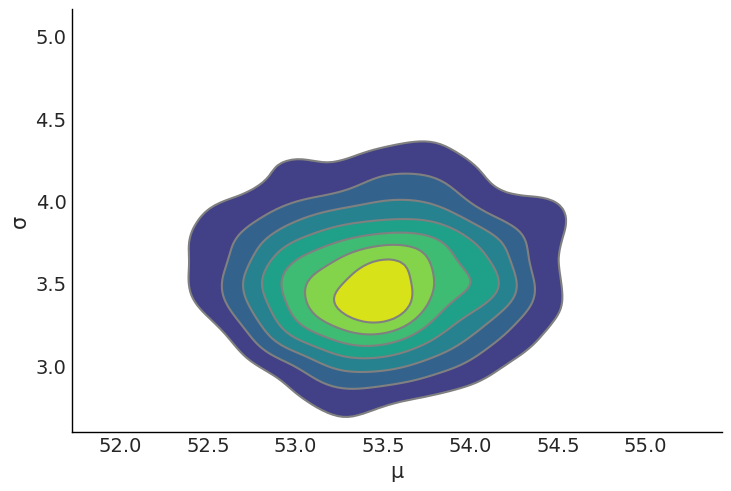

In [7]:
az.plot_pair(idata_g, kind='kde')
plt.savefig('B11197_02_10.png')

In [8]:

RANDOM_SEED = 58
rng = np.random.default_rng(RANDOM_SEED)

with model_g:
    pm.sample_posterior_predictive(idata_g,  extend_inferencedata=True, random_seed=rng)

In [9]:
idata_g.posterior['μ'].shape

(2, 1000)

In [10]:
az.summary(idata_g)

/usr/local/lib/python3.10/dist-packages/arviz/utils.py:184: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  numba_fn = numba.jit(**self.kwargs)(self.function)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
μ,53.480,0.525,52.494,54.461,0.012,0.008,1965.0,1250.0,1.0
σ,3.547,0.381,2.845,4.263,0.009,0.006,1839.0,1513.0,1.0


### Now that we have computed the posterior, we can use it to simulate data from it. Then we can check how consistent the simulated data is with the observed data. we generically call these types of comparisons posterior predictive checks, because we are using the posterior to make predictions and those predictions to check the model. In the following code, we are generating 100 predictions from the posterior, each one of the same size as the data.



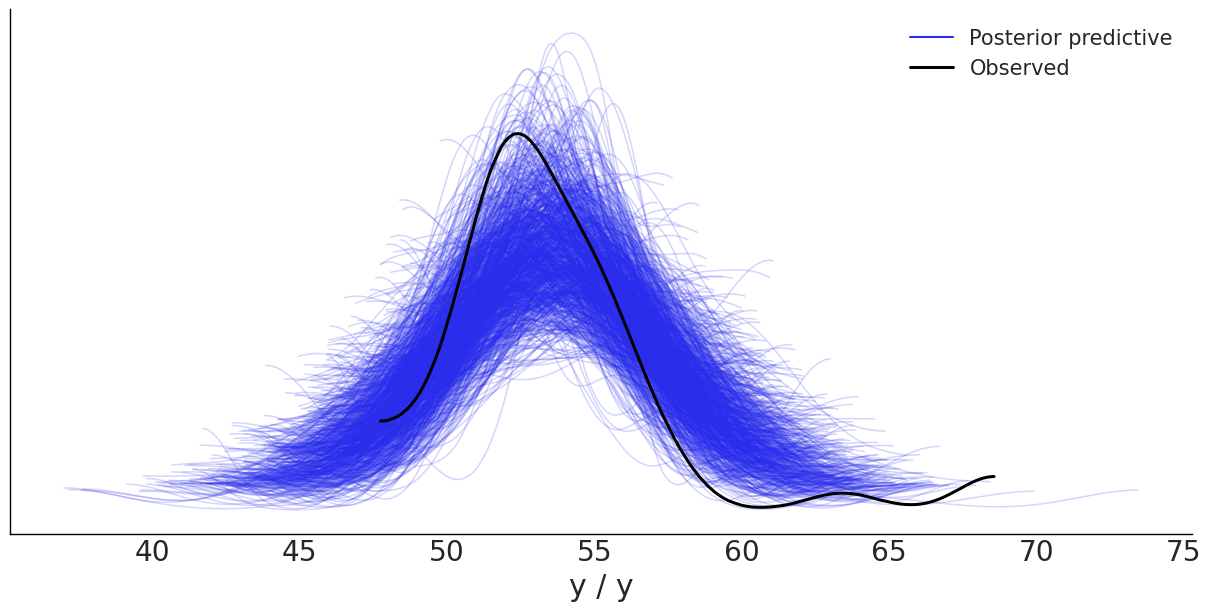

In [11]:
ax = az.plot_ppc(idata_g, num_pp_samples=1000, figsize=(12, 6), mean=False)
plt.savefig('B11197_02_11.png')

### Robust inferences

### T Distribution

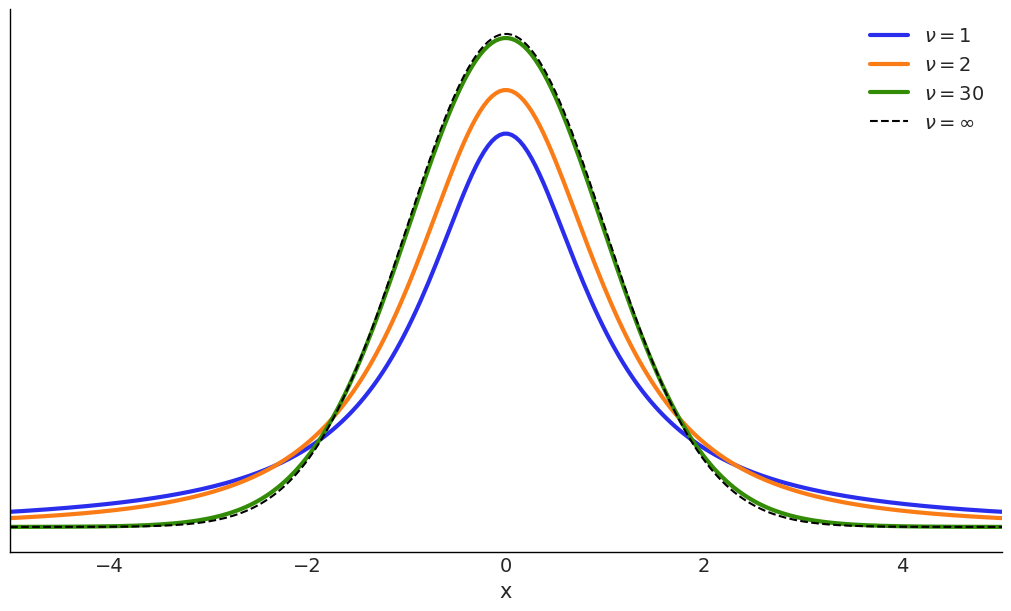

In [12]:
plt.figure(figsize=(10, 6))
x_values = np.linspace(-10, 10, 500)
for df in [1, 2, 30]:
    distri = stats.t(df)
    x_pdf = distri.pdf(x_values)
    plt.plot(x_values, x_pdf, label=fr'$\nu = {df}$', lw=3)

x_pdf = stats.norm.pdf(x_values)
plt.plot(x_values, x_pdf, 'k--', label=r'$\nu = \infty$')
plt.xlabel('x')
plt.yticks([])
plt.legend()
plt.xlim(-5, 5)
plt.savefig('B11197_02_12.png')

 <img src="B11197_02_13.png" width="500">

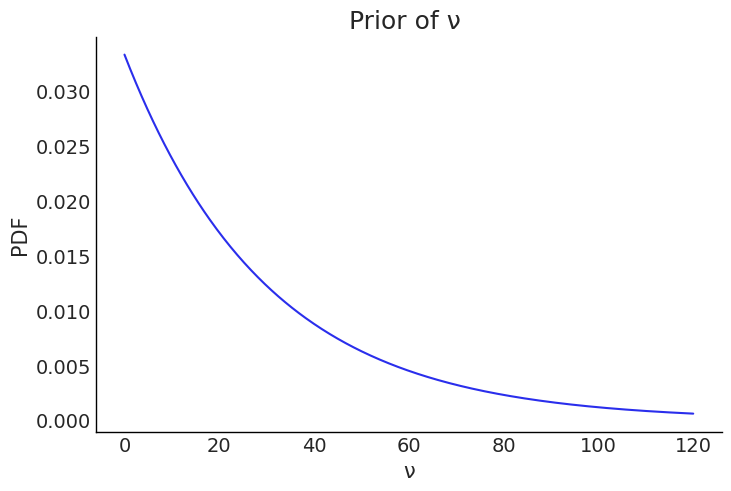

In [13]:
plt.figure()
x_vals = np.linspace(0,120,500)
y_vals = (1/30)*np.exp(-(1/30)*x_vals)
plt.plot(x_vals, y_vals)
plt.title('Prior of ν ', fontsize = 18)
plt.ylabel('PDF', fontsize = 15)
plt.xlabel('ν', fontsize = 15)
plt.show()

In [14]:
with pm.Model() as model_t:
    μ = pm.Uniform('μ', 40, 75)
    σ = pm.HalfNormal('σ', sigma=10)
    ν = pm.Exponential('ν', 1/30)
    y = pm.StudentT('y', mu=μ, sigma=σ, nu=ν, observed=data)
    idata_t = pm.sample(1000)

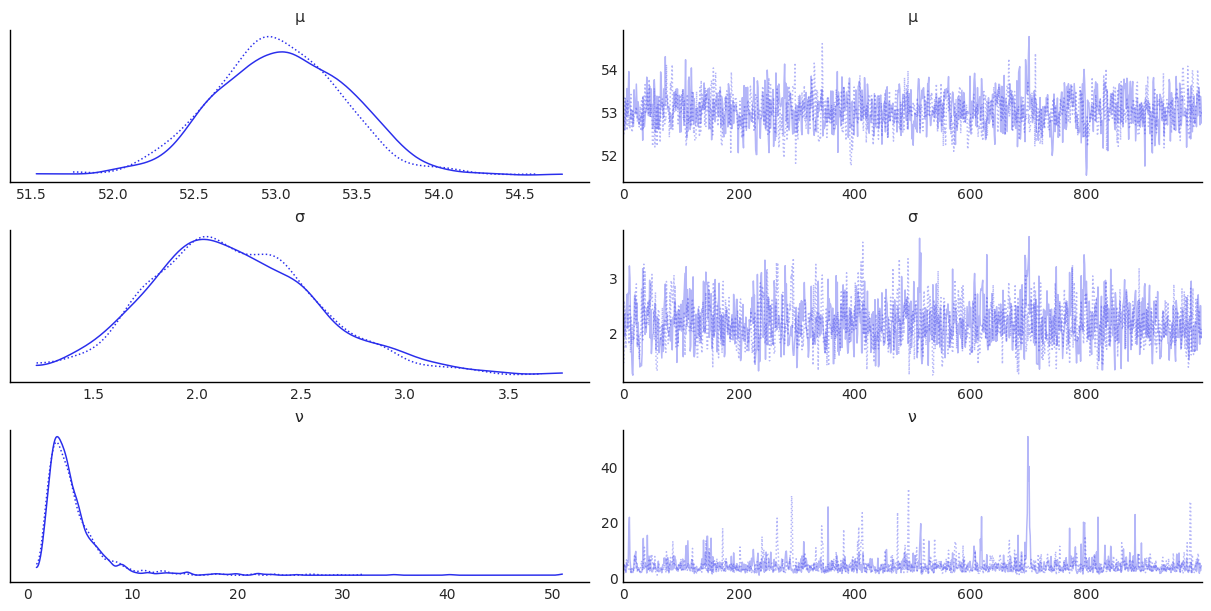

In [15]:
az.plot_trace(idata_t)
plt.savefig('B11197_02_14.png')

In [16]:
az.summary(idata_t)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
μ,53.029,0.402,52.322,53.804,0.012,0.008,1149.0,1157.0,1.0
σ,2.178,0.400,1.474,2.971,0.012,0.009,1155.0,1164.0,1.0
ν,4.447,3.420,1.346,9.038,0.126,0.096,1161.0,963.0,1.0


In [17]:
with model_t:
    pm.sample_posterior_predictive(idata_t, extend_inferencedata=True, random_seed=rng)

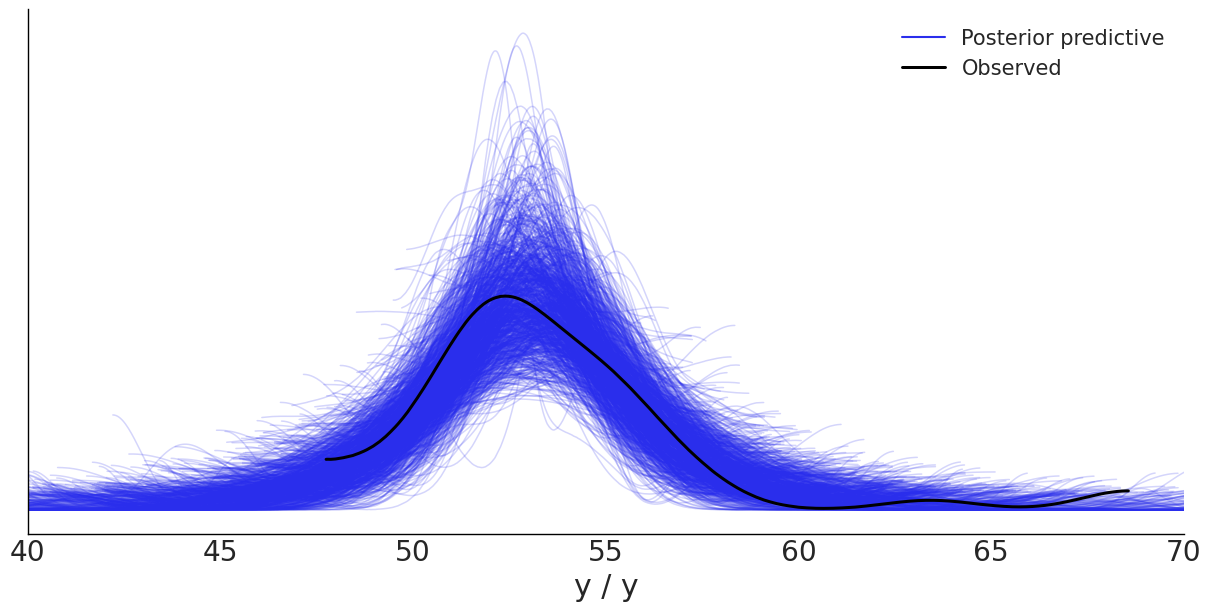

In [18]:
# pm.sample_posterior_predictive(idata_t, model=model_t, random_seed=123, extend_inferencedata=True)
az.plot_ppc(idata_t, figsize=(12, 6), mean=False, num_pp_samples=1000)
plt.xlim(40, 70)
plt.savefig('B11197_02_15.png')